# 유압펌프 이상탐지 EDA

- 입력: `press_data_normal.csv`(정상), `outlier_data.csv`(이상)
- 컬럼: TimeStamp, AI0_Vibration, AI1_Vibration, AI2_Current, Equipment_state
- 출력: 그림은 인라인 표시 + `eda_outputs/` 폴더에 png/csv 저장

순서: 1) 로드·기본정보 → 2) 결측/중복 → 3) 샘플링 간격 → 4) 기술통계 → 5) 시각화

## 0. 설정
재현성을 위해 seed 고정, 경로/컬럼/색상 상수 정의

In [1]:
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy.stats import kurtosis

%matplotlib inline
warnings.filterwarnings("ignore")

# 재현성을 위해 seed 고정
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# 경로: 노트북과 같은 폴더의 csv 사용
NORMAL_PATH = "press_data_normal.csv"
OUTLIER_PATH = "outlier_data.csv"
OUT_DIR = "eda_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

TIME_COL = "TimeStamp"
LABEL_COL = "Equipment_state"
CHANNELS = ["AI0_Vibration", "AI1_Vibration", "AI2_Current"]

# 정상/이상 색은 고정 순서 사용 (색약 대비 검증된 파랑/주황)
COLOR = {"normal": "#2a78d6", "outlier": "#eb6834"}
# 상관계수(-1~1)는 극성 데이터라 파랑-회색-빨강 diverging 팔레트 사용
DIVERGING_CMAP = LinearSegmentedColormap.from_list("corr_div", ["#2a78d6", "#f0efec", "#e34948"])

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams["axes.unicode_minus"] = False

## 1. 데이터 로드 및 기본 정보 확인
모델링 전에 데이터 크기/타입/라벨 분포를 알아야 전처리 방향이 정해짐. 저장 시 섞여 들어간 Unnamed 인덱스 컬럼은 자동 제거.

In [2]:
def load_data(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    # 'Unnamed: 0' 같은 인덱스 컬럼은 정보가 없으므로 제거
    unnamed = [c for c in df.columns if str(c).startswith("Unnamed")]
    if unnamed:
        df = df.drop(columns=unnamed)
        print(f"  - 인덱스 컬럼 제거: {unnamed}")
    # 시간 분석을 위해 TimeStamp를 datetime으로 변환
    df[TIME_COL] = pd.to_datetime(df[TIME_COL])
    return df


def basic_info(df: pd.DataFrame, name: str) -> None:
    print(f"\n--- {name} ---")
    print(f"shape   : {df.shape}")
    print(f"columns : {list(df.columns)}")
    print("dtypes  :")
    print(df.dtypes.to_string())
    print("label 분포 (Equipment_state):")
    print(df[LABEL_COL].value_counts(dropna=False).to_string())


normal = load_data(NORMAL_PATH)
outlier = load_data(OUTLIER_PATH)
basic_info(normal, "정상 데이터 (press_data_normal.csv)")
basic_info(outlier, "이상 데이터 (outlier_data.csv)")

# 두 파일이 실제로 다른 데이터인지 확인 (같으면 비교 EDA가 의미 없음)
if normal.shape == outlier.shape and normal.equals(outlier):
    print("\n[경고] 정상/이상 파일의 내용이 완전히 동일합니다. 이상 데이터 파일이 올바른지 확인하세요.")

# source 컬럼으로 출처를 구분한 통합 데이터 (boxplot 등에 사용)
normal["source"] = "normal"
outlier["source"] = "outlier"
combined = pd.concat([normal, outlier], ignore_index=True)

display(normal.head())
display(outlier.head())
display(pd.crosstab(combined["source"], combined[LABEL_COL]))

  - 인덱스 컬럼 제거: ['Unnamed: 0']
  - 인덱스 컬럼 제거: ['Unnamed: 0']

--- 정상 데이터 (press_data_normal.csv) ---
shape   : (20000, 5)
columns : ['TimeStamp', 'AI0_Vibration', 'AI1_Vibration', 'AI2_Current', 'Equipment_state']
dtypes  :
TimeStamp          datetime64[ns]
AI0_Vibration             float64
AI1_Vibration             float64
AI2_Current               float64
Equipment_state             int64
label 분포 (Equipment_state):
Equipment_state
0    20000

--- 이상 데이터 (outlier_data.csv) ---
shape   : (600, 5)
columns : ['TimeStamp', 'AI0_Vibration', 'AI1_Vibration', 'AI2_Current', 'Equipment_state']
dtypes  :
TimeStamp          datetime64[ns]
AI0_Vibration             float64
AI1_Vibration             float64
AI2_Current               float64
Equipment_state             int64
label 분포 (Equipment_state):
Equipment_state
1    600


,TimeStamp,AI0_Vibration,AI1_Vibration,AI2_Current,Equipment_state,source
0,2022-07-12 00:00:00.019,0.116967,-0.176403,192.338730,0,normal
1,2022-07-12 00:00:00.119,0.030080,-0.210895,217.004330,0,normal
2,2022-07-12 00:00:00.219,-0.045794,-0.029424,197.510620,0,normal
3,2022-07-12 00:00:00.319,0.047519,0.258642,156.607170,0,normal
4,2022-07-12 00:00:00.419,0.020351,0.173777,93.236934,0,normal


,TimeStamp,AI0_Vibration,AI1_Vibration,AI2_Current,Equipment_state,source
0,2022-07-17 10:51:07.943,0.293727,-0.540554,21.457675,1,outlier
1,2022-07-17 10:51:08.043,1.070320,-0.557382,-44.107442,1,outlier
2,2022-07-17 10:51:08.143,0.908692,0.063108,25.033954,1,outlier
3,2022-07-17 10:51:08.243,0.235921,0.509321,-101.327910,1,outlier
4,2022-07-17 10:51:16.724,0.315538,0.205315,34.570698,1,outlier


Equipment_state,0,1
source,,
normal,20000,0
outlier,0,600


## 2. 결측치 / 중복 확인
결측은 보간/제거 결정에, 중복 행은 학습 데이터 누수·편향 원인이 되므로 사전에 파악.

In [3]:
for name, df in [("정상", normal), ("이상", outlier)]:
    print(f"\n--- {name} ---")
    print("결측치 개수:")
    print(df.isna().sum().to_string())
    # source 컬럼은 우리가 붙인 것이므로 제외하고 중복 판단
    print(f"전체 행 중복      : {df.drop(columns='source').duplicated().sum()}건")
    print(f"TimeStamp 중복    : {df[TIME_COL].duplicated().sum()}건")


--- 정상 ---
결측치 개수:
TimeStamp          0
AI0_Vibration      0
AI1_Vibration      0
AI2_Current        0
Equipment_state    0
source             0
전체 행 중복      : 1건
TimeStamp 중복    : 1건

--- 이상 ---
결측치 개수:
TimeStamp          0
AI0_Vibration      0
AI1_Vibration      0
AI2_Current        0
Equipment_state    0
source             0
전체 행 중복      : 0건
TimeStamp 중복    : 0건


## 3. 샘플링 간격 분석
시계열 모델(윈도우 크기, 주파수 기반 특징)은 등간격을 가정하므로 간격의 규칙성을 반드시 확인. 중앙값 대비 ±20% 벗어나는 구간을 불규칙으로 정의.

In [4]:
interval_rows = []
for name, df in [("normal", normal), ("outlier", outlier)]:
    ts = df[TIME_COL].sort_values()
    diff = ts.diff().dt.total_seconds().dropna()
    med = diff.median()
    # 중앙값 대비 ±20% 벗어나는 구간을 불규칙으로 정의
    irregular = diff[(diff < med * 0.8) | (diff > med * 1.2)]
    print(f"\n--- {name} ---")
    print(f"기간      : {ts.min()} ~ {ts.max()}")
    print(f"평균 간격 : {diff.mean():.4f} s  (≈ {1 / diff.mean():.2f} Hz)")
    print(f"중앙값    : {med:.4f} s")
    print(f"최소 간격 : {diff.min():.4f} s")
    print(f"최대 간격 : {diff.max():.4f} s")
    print(f"표준편차  : {diff.std():.4f} s")
    print(f"불규칙 구간(중앙값 ±20% 초과): {len(irregular)}건 / {len(diff)}")
    if len(irregular) > 0:
        print("불규칙 구간 예시(상위 5개, 초):")
        print(irregular.sort_values(ascending=False).head(5).to_string())
    interval_rows.append({"source": name, "mean_s": diff.mean(), "median_s": med,
                          "min_s": diff.min(), "max_s": diff.max(), "std_s": diff.std(),
                          "n_irregular": len(irregular)})

interval_df = pd.DataFrame(interval_rows)
interval_df.to_csv(os.path.join(OUT_DIR, "sampling_interval.csv"), index=False)
display(interval_df)


--- normal ---
기간      : 2022-07-12 00:00:00.019000 ~ 2022-07-12 01:16:55.828000
평균 간격 : 0.2308 s  (≈ 4.33 Hz)
중앙값    : 0.1000 s
최소 간격 : 0.0000 s
최대 간격 : 16.6430 s
표준편차  : 0.8568 s
불규칙 구간(중앙값 ±20% 초과): 599건 / 19999
불규칙 구간 예시(상위 5개, 초):
19550    16.643
19377    16.630
13266    16.497
16363    16.456
923      15.394

--- outlier ---
기간      : 2022-07-17 10:51:07.943000 ~ 2022-07-17 10:53:53.540000
평균 간격 : 0.2765 s  (≈ 3.62 Hz)
중앙값    : 0.1000 s
최소 간격 : 0.1000 s
최대 간격 : 8.5720 s
표준편차  : 1.0390 s
불규칙 구간(중앙값 ±20% 초과): 20건 / 599
불규칙 구간 예시(상위 5개, 초):
585    8.572
280    8.546
4      8.481
415    8.455
153    8.391


,source,mean_s,median_s,min_s,max_s,std_s,n_irregular
0,normal,0.230802,0.1,0.0,16.643,0.856847,599
1,outlier,0.276456,0.1,0.1,8.572,1.039043,20


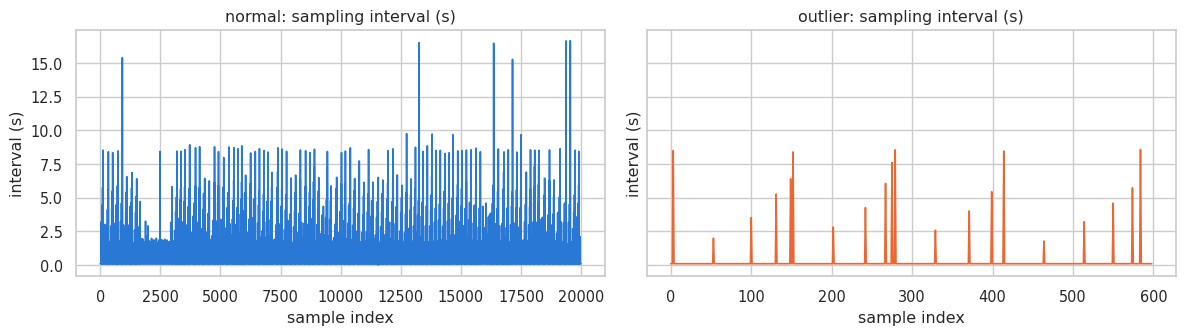

In [5]:
# 간격 시각화: 불규칙 구간이 특정 시점에 몰려 있는지 눈으로 확인
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, (name, df) in zip(axes, [("normal", normal), ("outlier", outlier)]):
    diff = df[TIME_COL].sort_values().diff().dt.total_seconds().dropna()
    ax.plot(diff.values, color=COLOR[name], linewidth=1.2)
    ax.set_title(f"{name}: sampling interval (s)")
    ax.set_xlabel("sample index")
    ax.set_ylabel("interval (s)")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "03_sampling_interval.png"), dpi=130)
plt.show()

## 4. 기술통계 (정상 vs 이상)
평균/분산 차이는 진폭 기반 특징의 근거, kurtosis는 충격성(impulsive) 신호 여부를 시사하여 특징 설계 방향을 정해줌.

In [6]:
stat_rows = []
for name, df in [("normal", normal), ("outlier", outlier)]:
    for ch in CHANNELS:
        x = df[ch].astype(float)
        stat_rows.append({"source": name, "channel": ch,
                          "mean": x.mean(), "std": x.std(), "min": x.min(), "max": x.max(),
                          # fisher=True → 정규분포의 kurtosis가 0이 되는 기준
                          "kurtosis": kurtosis(x, fisher=True, nan_policy="omit")})
stats_df = pd.DataFrame(stat_rows)
stats_df.to_csv(os.path.join(OUT_DIR, "descriptive_stats.csv"), index=False)

# 채널별로 정상/이상을 나란히 보기
display(stats_df.set_index(["channel", "source"]).sort_index().round(4))

# (이상 − 정상) 차이: 어느 채널/통계가 가장 갈리는지 한눈에 확인
cols = ["mean", "std", "min", "max", "kurtosis"]
diff_stats = (stats_df[stats_df.source == "outlier"].set_index("channel")[cols]
              - stats_df[stats_df.source == "normal"].set_index("channel")[cols])
print("(이상 − 정상) 차이:")
display(diff_stats.round(4))

mean       std       min       max  kurtosis
channel       source                                                  
AI0_Vibration normal   -0.0001    0.0706   -0.3146    0.3517    0.5336
              outlier   0.0076    0.4479   -1.5027    1.8032    2.4586
AI1_Vibration normal   -0.0001    0.1189   -0.3665    0.3998    0.3908
              outlier  -0.0081    0.2412   -0.7513    0.5093    0.5110
AI2_Current   normal    1.4462  122.6645 -271.5683  273.2350   -0.8628
              outlier  57.3297  153.1726 -399.3512  538.8260    0.3256

(이상 − 정상) 차이:


,mean,std,min,max,kurtosis
channel,,,,,
AI0_Vibration,0.0077,0.3773,-1.1882,1.4515,1.9249
AI1_Vibration,-0.0080,0.1223,-0.3848,0.1095,0.1201
AI2_Current,55.8835,30.5081,-127.7828,265.5910,1.1885


## 5. 시각화
### 5-1. 채널별 시계열 파형
진동·전류의 시간 패턴(주기성, 스파이크, 드리프트)을 직접 눈으로 확인. 왼쪽 정상, 오른쪽 이상.

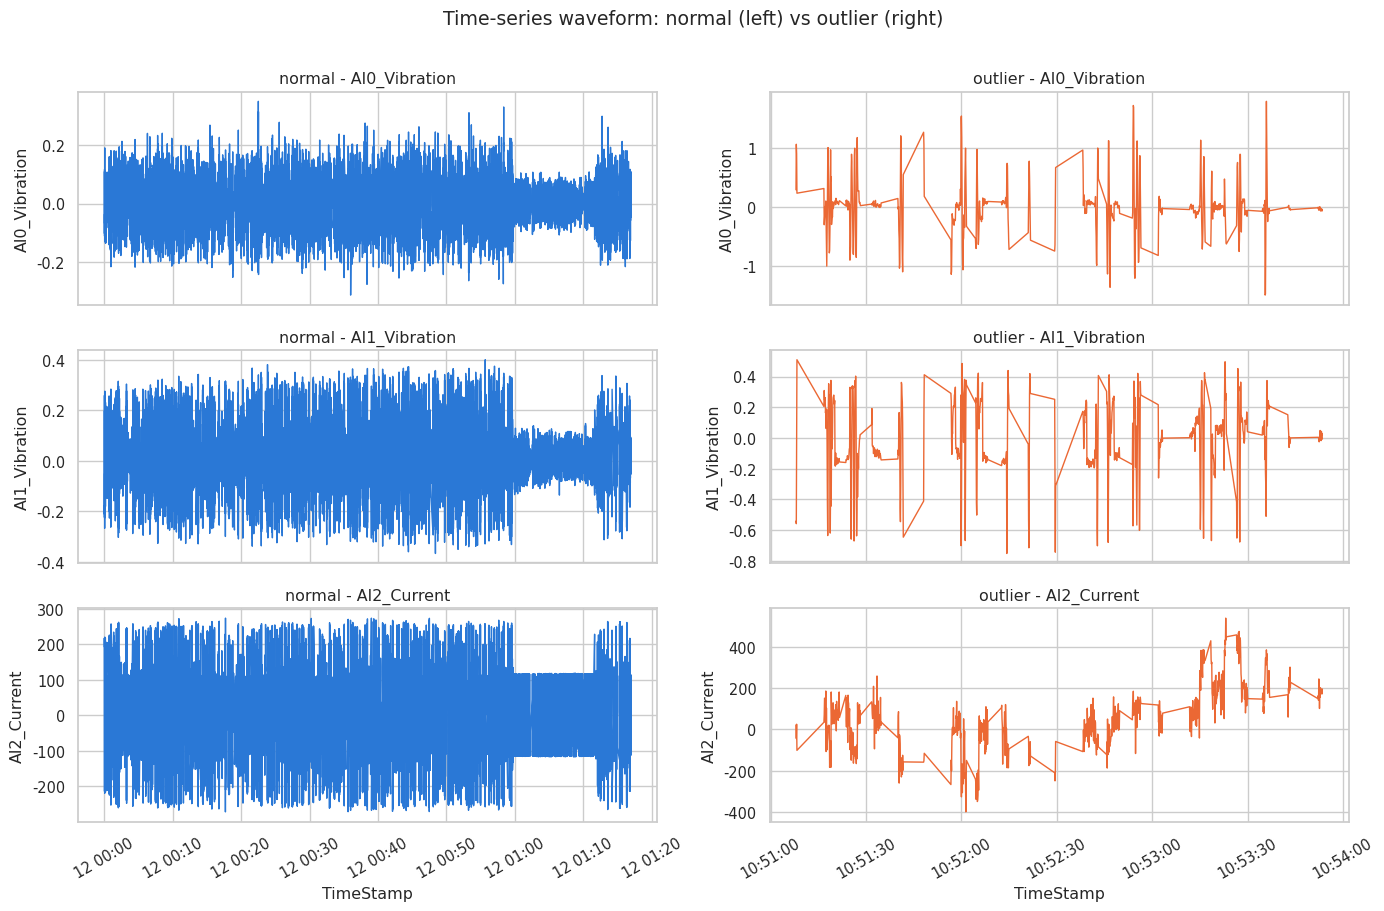

In [7]:
fig, axes = plt.subplots(len(CHANNELS), 2, figsize=(14, 9), sharex="col")
for i, ch in enumerate(CHANNELS):
    for j, (name, df) in enumerate([("normal", normal), ("outlier", outlier)]):
        ax = axes[i, j]
        ax.plot(df[TIME_COL], df[ch], color=COLOR[name], linewidth=1.0)
        ax.set_title(f"{name} - {ch}")
        ax.set_ylabel(ch)
        if i == len(CHANNELS) - 1:
            ax.set_xlabel("TimeStamp")
            ax.tick_params(axis="x", rotation=30)
fig.suptitle("Time-series waveform: normal (left) vs outlier (right)", y=1.01)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "05_1_timeseries.png"), dpi=130, bbox_inches="tight")
plt.show()

두 파일의 시간대가 다를 수 있어 샘플 인덱스 기준으로 겹쳐 그려 진폭 스케일 차이를 직접 비교.

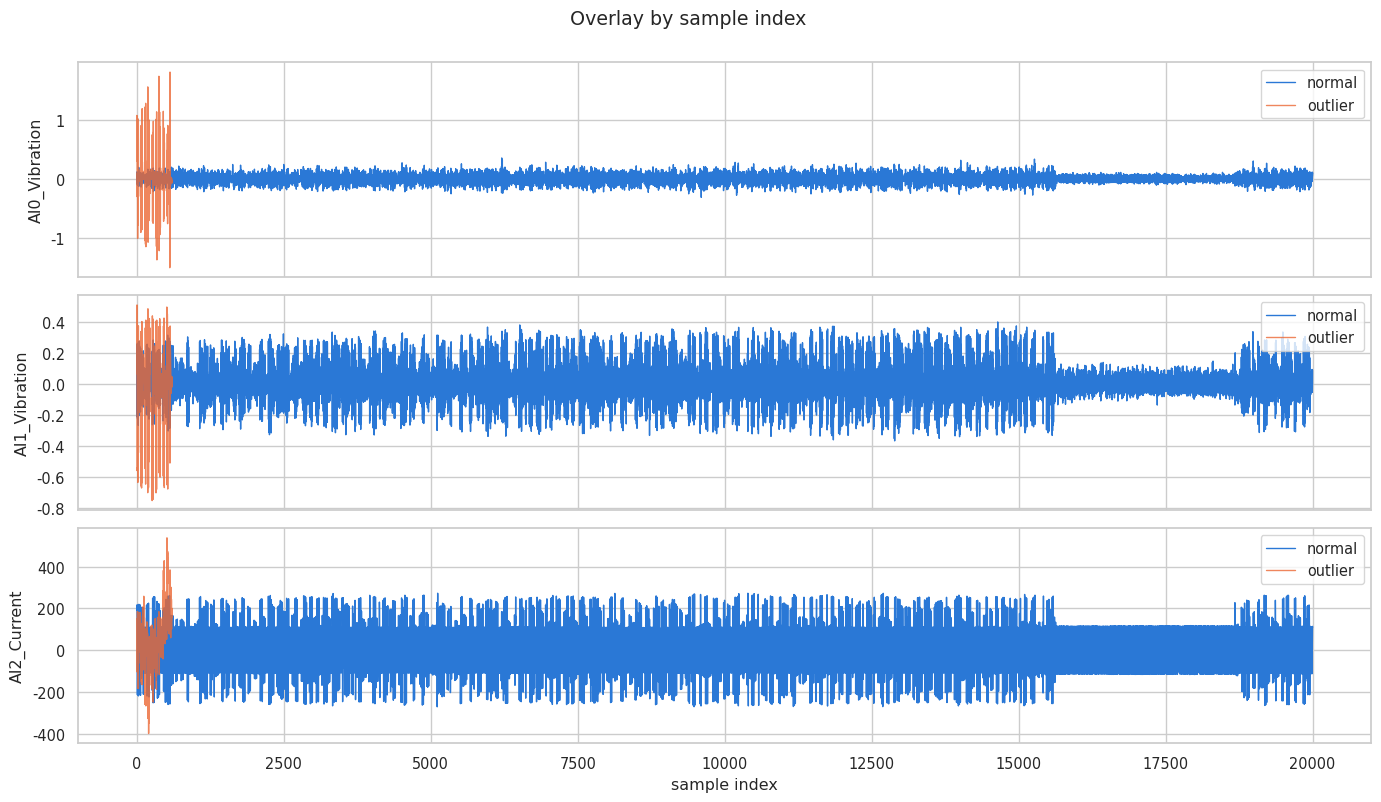

In [8]:
fig, axes = plt.subplots(len(CHANNELS), 1, figsize=(14, 8), sharex=True)
for ax, ch in zip(axes, CHANNELS):
    ax.plot(normal[ch].values, color=COLOR["normal"], linewidth=1.0, label="normal")
    ax.plot(outlier[ch].values, color=COLOR["outlier"], linewidth=1.0, alpha=0.8, label="outlier")
    ax.set_ylabel(ch)
    ax.legend(loc="upper right")
axes[-1].set_xlabel("sample index")
fig.suptitle("Overlay by sample index", y=1.0)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "05_1b_timeseries_overlay.png"), dpi=130, bbox_inches="tight")
plt.show()

### 5-2. 분포 비교 (histogram + boxplot)
평균 이동인지, 분산 확대인지, 꼬리(outlier)가 늘어난 것인지 분포 형태로 판단.

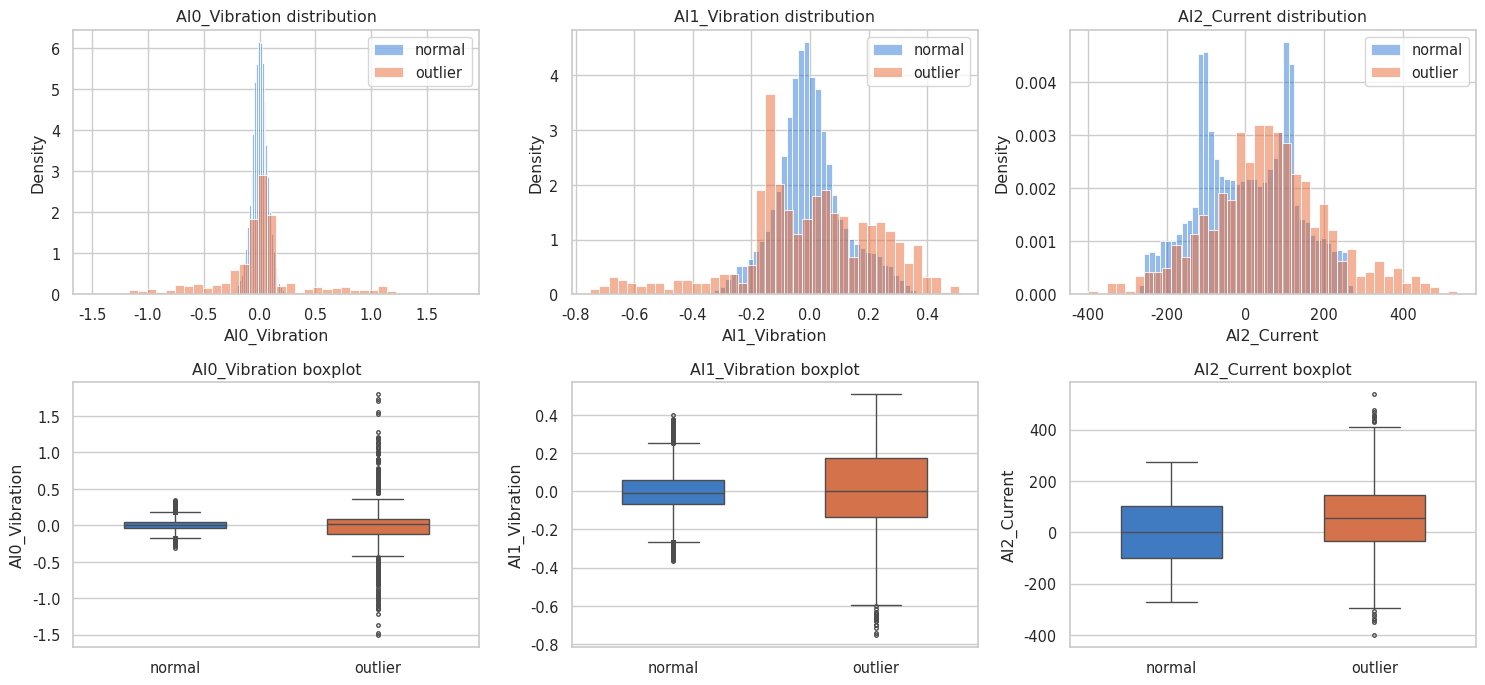

In [9]:
fig, axes = plt.subplots(2, len(CHANNELS), figsize=(15, 7))
for j, ch in enumerate(CHANNELS):
    # 히스토그램: 밀도 기준으로 겹쳐 그려 형태 비교
    ax = axes[0, j]
    sns.histplot(normal[ch], color=COLOR["normal"], label="normal", stat="density",
                 bins=40, alpha=0.5, ax=ax, edgecolor=None)
    sns.histplot(outlier[ch], color=COLOR["outlier"], label="outlier", stat="density",
                 bins=40, alpha=0.5, ax=ax, edgecolor=None)
    ax.set_title(f"{ch} distribution")
    ax.legend()
    # 박스플롯: 중앙값/IQR/이상치 비교
    ax = axes[1, j]
    sns.boxplot(data=combined, x="source", y=ch, order=["normal", "outlier"],
                palette=[COLOR["normal"], COLOR["outlier"]], width=0.5, fliersize=2.5, ax=ax)
    ax.set_title(f"{ch} boxplot")
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "05_2_distribution.png"), dpi=130)
plt.show()

### 5-3. 채널 간 상관관계 heatmap (정상 / 이상)
이상 상태에서 채널 간 결합 구조가 바뀌는지 확인 → 다변량(공분산 기반) 특징의 유효성 판단.


normal 상관행렬:
               AI0_Vibration  AI1_Vibration  AI2_Current
AI0_Vibration          1.000          0.368        0.004
AI1_Vibration          0.368          1.000        0.001
AI2_Current            0.004          0.001        1.000

outlier 상관행렬:
               AI0_Vibration  AI1_Vibration  AI2_Current
AI0_Vibration          1.000         -0.381        0.012
AI1_Vibration         -0.381          1.000        0.034
AI2_Current            0.012          0.034        1.000


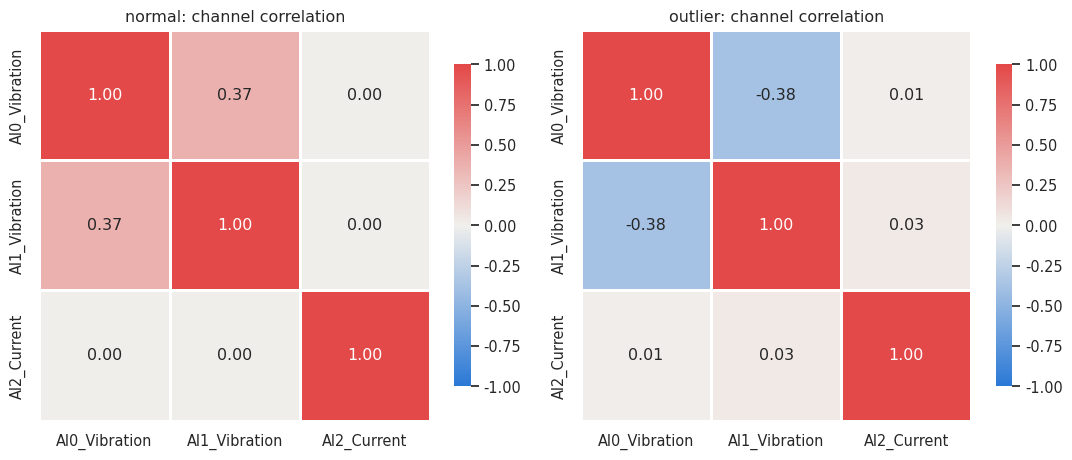

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, df) in zip(axes, [("normal", normal), ("outlier", outlier)]):
    corr = df[CHANNELS].corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIVERGING_CMAP, vmin=-1, vmax=1, center=0,
                square=True, linewidths=2, linecolor="white", cbar_kws={"shrink": 0.8}, ax=ax)
    ax.set_title(f"{name}: channel correlation")
    print(f"\n{name} 상관행렬:")
    print(corr.round(3).to_string())
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "05_3_correlation_heatmap.png"), dpi=130)
plt.show()

## 저장된 결과물 확인

In [11]:
print(f"저장 위치: {os.path.abspath(OUT_DIR)}")
for f in sorted(os.listdir(OUT_DIR)):
    print("  -", f)

저장 위치: /home/iai/Desktop/Yerin/KAMP/eda_outputs
  - 03_sampling_interval.png
  - 05_1_timeseries.png
  - 05_1b_timeseries_overlay.png
  - 05_2_distribution.png
  - 05_3_correlation_heatmap.png
  - descriptive_stats.csv
  - sampling_interval.csv
